In [93]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import re
import cv2

ROOT = Path("/Users/marcellobullo/research/FINAL/github/djscc-playground")
RESULTS_DIR = ROOT / "results"
EXP_DIR = RESULTS_DIR / "djscc-psnr-vs-snr"

SNR_DIR_RE = re.compile(r"snr_?(-?\d+)\s*dB", re.IGNORECASE)
RESULT_IDX_RE = re.compile(r"_(\d+)\.png$", re.IGNORECASE)

WIDTH = 768
HEIGHT = 512

match = "index" 

In [146]:
def load_rgb(path: Path, width: int, height: int) -> np.ndarray:
    """Load an image as an HxWx3 uint8 array (drops alpha if present)."""
    #return np.asarray(Image.open(path).convert("RGB"))
    image_bgr = np.array(Image.open(path))
    return cv2.resize(image_bgr, (width, height))


def load_originals(originals_dir: Path, width: int, height: int) -> dict[str, np.ndarray]:
    originals = {}
    for p in sorted(originals_dir.glob("*.png")):
        originals[p.stem] = load_rgb(p, width, height)
    if not originals:
        raise SystemExit(f"No PNG originals found in {originals_dir}")
    return originals

def psnr(a: np.ndarray, b: np.ndarray) -> float:
    """Standard RGB PSNR in dB (MAX=255). Returns inf for identical images."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10.0 * np.log10((255.0 ** 2) / mse)

In [147]:
orig_path = "/Users/marcellobullo/Downloads/kodak_dataset"

originals = load_originals(Path(orig_path), WIDTH, HEIGHT)
print(f"Loaded {len(originals)} originals from {Path(orig_path)}")

Loaded 24 originals from /Users/marcellobullo/Downloads/kodak_dataset


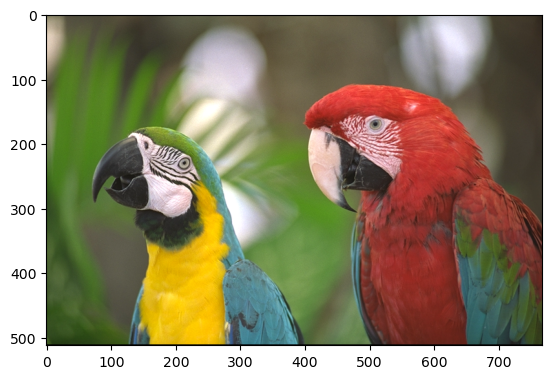

In [148]:
img_idx = 23
img = originals[f"kodim{img_idx:02}"]
plt.imshow(img)
plt.show()

In [149]:
snr_dirs = []
for d in sorted(EXP_DIR.iterdir()):
    if not d.is_dir():
        continue
    m = SNR_DIR_RE.search(d.name)
    if m:
        snr_dirs.append((int(m.group(1)), d))
snr_dirs.sort(key=lambda t: t[0])
if not snr_dirs:
    raise SystemExit(f"No snr_*dB sub-folders found in {EXP_DIR}")

snr_dirs

[(0,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_0dB')),
 (4,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_4dB')),
 (8,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_8dB')),
 (12,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_12dB')),
 (16,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_16dB')),
 (20,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_20dB')),
 (24,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_24dB')),
 (28,
  PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/djscc-psnr-vs-snr/snr_28dB'))]

In [150]:
rows = []          # per-image records for the CSV
summary = [] 

for snr, d in snr_dirs:
    vals = []
    print(f"\nSNR {snr:>3} dB  ({d.name})")
    for img_path in sorted(d.glob("*.png")):
        #print("image path: ", img_path)
        recon = load_rgb(img_path, WIDTH, HEIGHT)
        img_index = int(img_path.with_suffix("").name.split("_")[1])
        original_name = f"kodim{img_index:02d}"
        original_img = originals.get(original_name)
        PSNR = psnr(recon, original_img)

        vals.append(PSNR)
        rows.append({"snr_db": snr, "result": img_path.name,
                        "matched_original": original_name,
                        "psnr_db": round(PSNR, 4)})
        #print(f"  {img_path.name:<18} -> {original_name}  PSNR {PSNR:6.2f} dB")
    if vals:
        arr = np.asarray(vals)
        summary.append((snr, float(arr.mean()), float(arr.std()), len(arr)))

summary


SNR   0 dB  (snr_0dB)

SNR   4 dB  (snr_4dB)

SNR   8 dB  (snr_8dB)

SNR  12 dB  (snr_12dB)

SNR  16 dB  (snr_16dB)

SNR  20 dB  (snr_20dB)

SNR  24 dB  (snr_24dB)

SNR  28 dB  (snr_28dB)


[(0, 15.03633736483272, 1.6489132427757998, 24),
 (4, 17.876445871914864, 1.5819952367303576, 24),
 (8, 21.616607113605824, 1.560807220967932, 24),
 (12, 24.515029192420556, 2.002907898050137, 24),
 (16, 25.75773867565344, 2.231917453589033, 24),
 (20, 26.360653605462357, 2.296408816414638, 24),
 (24, 26.58438419700514, 2.352526892858106, 24),
 (28, 26.61327966348034, 2.3825043646581956, 24)]

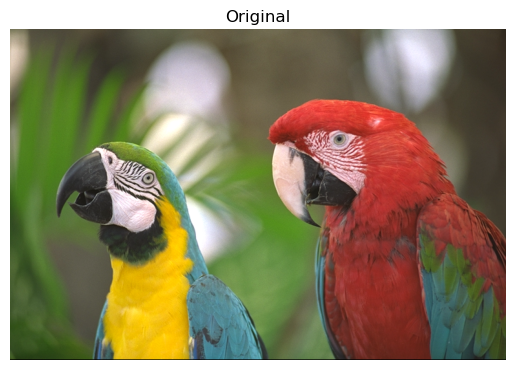

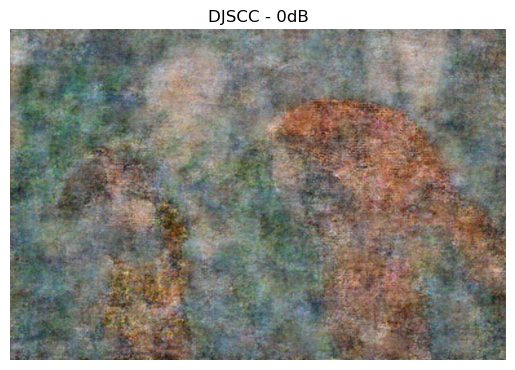

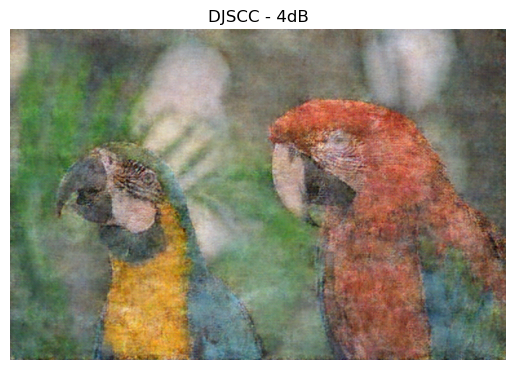

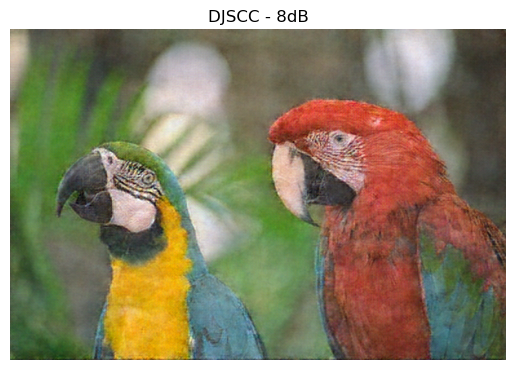

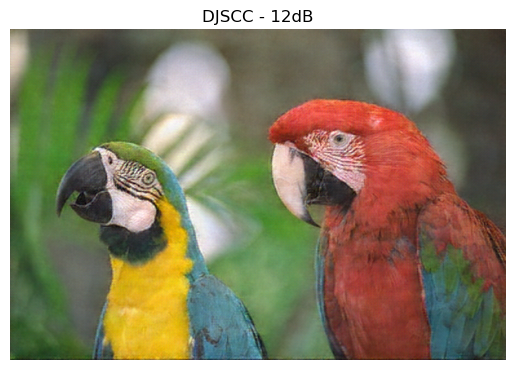

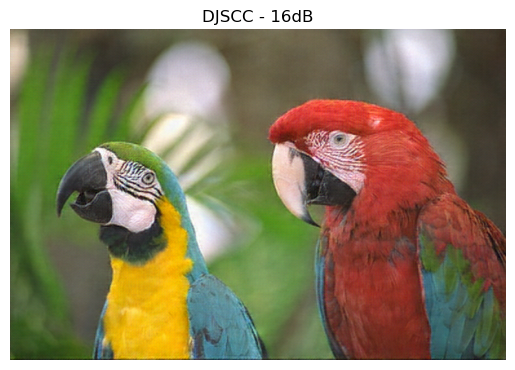

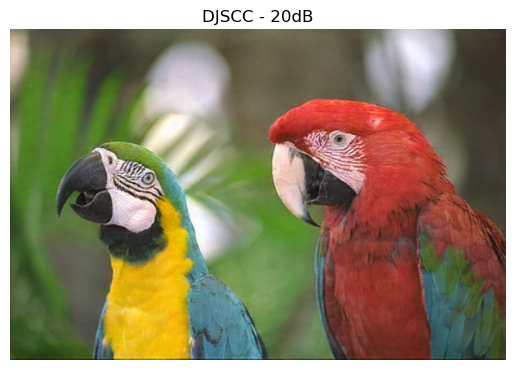

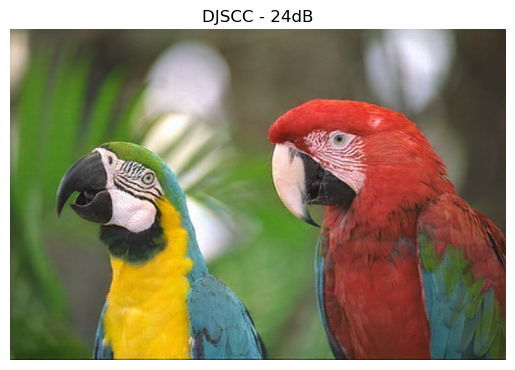

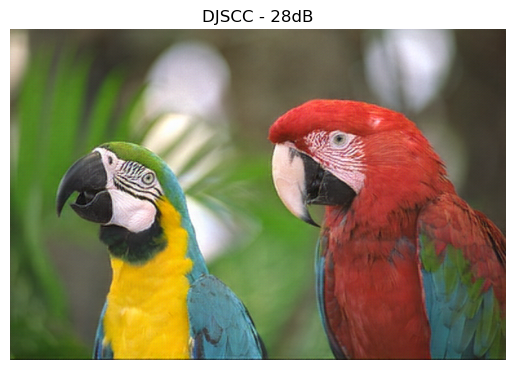

In [168]:
img_idx = 23
img_orig = originals[f"kodim{img_idx:02}"]

plt.imshow(img_orig)
plt.title("Original")
plt.axis('off')
plt.show()

for snr, d in snr_dirs:

    rec_images = sorted(d.glob("*.png"))
    img_rec = load_rgb(rec_images[img_idx-1], WIDTH, HEIGHT) 



    plt.imshow(img_rec)
    plt.title("DJSCC - {}dB".format(snr))
    plt.axis('off')
    plt.show()

[]

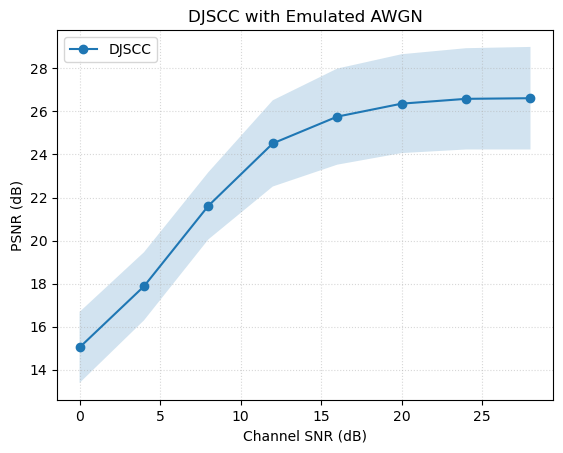

In [169]:
snrs = np.array([s[0] for s in summary])
means = np.array([s[1] for s in summary])
stds = np.array([s[2] for s in summary])

plt.plot(snrs, means, "o-", label="DJSCC")
plt.fill_between(snrs, means+stds, means-stds, alpha=0.2)

plt.grid(linestyle=":", alpha=0.5)

plt.xlabel("Channel SNR (dB)")
plt.ylabel("PSNR (dB)")
plt.title("DJSCC with Emulated AWGN")
plt.legend()
plt.plot()

## Alignment